# v9 — **Revalidation: which pillars actually predict?**
Continues from HEAD `e5e94ad` (v8 four-pillar implementation). Nothing from v1–v8 is overwritten; this is an additional layer whose job is **falsification**, not feature generation.

## The concern driving this phase
Discovery statistics run 1.5–2+ while validation statistics fall below 1. That pattern is the signature of overfitting, selection bias, or an unstable relationship. The question is not "does the composite improve?" but **"which individual signals carry out-of-sample information?"**

## Rules for this phase
* **Identical sample for every comparison.** All statistics below use one common window where all signals are valid.
* **Add-one Monte Carlo p-values throughout**: $p=(1+\#\{null \ge obs\})/(1+N)$. A simulated p is never reported as zero. *(v8 reported an end-to-end p of 0.000 — corrected here.)*
* **HAC/Newey-West** standard errors with lags = horizon, plus **moving-block bootstrap** confidence intervals, because 3M and 6M forward returns overlap.
* **Nothing is called validated on a discovery t-stat.** A validation t below 1 is not validation.
* **Multiplicity corrections are labelled conditional** where the v1–v7 search history cannot be reconstructed into the null.

## A note on the price series (addresses the "reconstructed price" concern)
The supplied `Price_data_all_countries.xlsx` contains **P/E values, not prices** — confirmed in v4. Price is recovered as $P = (P/E)\times EPS$, which is an **accounting identity**, not a proxy: $P/E \equiv P/EPS$.
v4 §12b verified the recovered US series against the **actual S&P 500**: mean absolute difference **0.04 pp** across eight well-known months, annualised vol 15.2 %, 2008-09 drawdown −52.6 %, cross-market correlations 0.61–0.84.
So the price observations are genuine. **The legitimate residual concern is different and is addressed directly in §5:** price momentum mechanically decomposes into a P/E part and an EPS part, so it may overlap with the valuation and micro pillars. That is tested, not assumed away.
No traded-volume data exists in the dataset, so **no VWAP construction is attempted.**

## 0. Setup, data, and point-in-time treatment

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import spearmanr
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 240
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v9'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
SEED = 7; NBOOT = 5000; NPERM = 2000
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   y2='USGGT02Y Index', oas='LF98OAS Index',  fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  y2='GDBR2 Index',    oas='LECPOAS Index', fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), y2='GUKG2 Index',    oas='LC61OAS Index', fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', oas='LECPOAS Index', fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), y2='GJGB2 Index',    oas='LJC1OAS Index', fx=('USDJPY BGN Curncy', 'invert')),
}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
def load(s):
    d = monthly(pd.read_excel(ROOT/'data'/'raw'/s['file']))
    o = pd.DataFrame({'pe': d['BEst P/E Ratio'], 'eps': d[s['eps']], 'y2': d[s['y2']], 'oas': d[s['oas']]})
    o['fci'] = s['fci'][1] * d[s['fci'][0]]
    o['fx'] = 1.0 if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return o
fr = {c: load(SPEC[c]) for c in COUNTRIES}
IDX = pd.period_range(max(fr[c].pe.first_valid_index() for c in COUNTRIES), min(fr[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, Y2, OAS, FCI, FX = [pd.DataFrame({c: fr[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'y2', 'oas', 'fci', 'fx')]
AS_OF = IDX[-1]; PX = PE * EPS; PX_USD = PX * FX; R_USD = PX_USD.pct_change()

### Point-in-time availability and data completeness

In [2]:
PIT = pd.DataFrame([
 {'Input': 'BEst P/E Ratio', 'Source timing': 'market price / live consensus', 'Known at month-end?': 'Yes', 'Lag applied': '0',
  'Comparability': 'same field all 5 markets'},
 {'Input': 'Forward EPS', 'Source timing': 'live analyst consensus', 'Known at month-end?': 'Yes', 'Lag applied': '0',
  'Comparability': 'US uses Monthly_EPS, others BEst EPS - FLAGGED (v4 §12b: P/E x EPS reproduces SPX exactly, so it must be the same forward consensus)'},
 {'Input': 'Financial Conditions Index', 'Source timing': 'daily, real-time', 'Known at month-end?': 'Yes', 'Lag applied': '0',
  'Comparability': 'GS FCI for US/UK/CH/JP, Bloomberg BFCIEU for EZ - different scales, orientation verified vs VIX in v2; CH uses the euro-area index'},
 {'Input': '2Y yield / credit OAS / FX', 'Source timing': 'market, real-time', 'Known at month-end?': 'Yes', 'Lag applied': '0',
  'Comparability': 'CH credit spread duplicates EZ (LECPOAS)'},
 {'Input': 'PMI', 'Source timing': 'published ~1st business day of NEXT month', 'Known at month-end?': 'No', 'Lag applied': '1 month',
  'Comparability': 'same concept, different providers'},
]).set_index('Input')
display(PIT)
print('UNVERIFIABLE: whether the stored consensus series are point-in-time snapshots or restated. No vendor metadata in the workbooks.')
comp = pd.DataFrame({'P/E': PE.notna().sum(), 'EPS': EPS.notna().sum(), 'FCI': FCI.notna().sum(), '2Y': Y2.notna().sum(), 'OAS': OAS.notna().sum(), 'FX': FX.notna().sum()})
comp['months in panel'] = len(IDX)
display(comp)

,Source timing,Known at month-end?,Lag applied,Comparability
Input,,,,
BEst P/E Ratio,market price / live consensus,Yes,0,same field all 5 markets
Forward EPS,live analyst consensus,Yes,0,"US uses Monthly_EPS, others BEst EPS - FLAGGED..."
Financial Conditions Index,"daily, real-time",Yes,0,"GS FCI for US/UK/CH/JP, Bloomberg BFCIEU for E..."
2Y yield / credit OAS / FX,"market, real-time",Yes,0,CH credit spread duplicates EZ (LECPOAS)
PMI,published ~1st business day of NEXT month,No,1 month,"same concept, different providers"


UNVERIFIABLE: whether the stored consensus series are point-in-time snapshots or restated. No vendor metadata in the workbooks.


,P/E,EPS,FCI,2Y,OAS,FX,months in panel
US,245,245,245,245,245,245,245
Eurozone,245,245,245,245,245,245,245
UK,245,245,245,245,245,245,245
Switzerland,245,245,245,245,245,245,245
Japan,245,245,245,245,245,245,245


## 1. Signal definitions and the common sample
Five signals under test. Pure 3M price momentum is added as the user requested, so the technical pillar is not judged only on its gated variant.

In [3]:
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
own_sd = lambda d, w=36: d / d.expanding(w).std()
EPSG12 = EPS / EPS.shift(12) - 1
DEFS = {
 'MACRO_fci6':  ('6M change in oriented FCI, scaled by its own expanding sd', 'easier financing supports risk assets', '+', own_sd(FCI - FCI.shift(6))),
 'MICRO_eps6':  ('6M % change in forward consensus EPS', 'analyst revisions persist', '+', EPS / EPS.shift(6) - 1),
 'VAL_v3':      ('minus 6M change in log P/E, own-sd scaled', 'a compressed multiple rebounds', '+', -own_sd(np.log(PE / PE.shift(6)))),
 'TECH_t3':     ('12-1M price momentum, gated to markets with positive 12M EPS growth', 'trend confirmed by fundamentals', '+', (PX.shift(1) / PX.shift(13) - 1).where(EPSG12 > 0, 0.0)),
 'TECH_mom3':   ('pure 3M price momentum (no gate)', 'short-horizon trend persistence', '+', PX / PX.shift(3) - 1),
}
Z = {k: cs_z(v[3].reindex(IDX)) for k, v in DEFS.items()}
display(pd.DataFrame([{'signal': k, 'formula': v[0], 'economic interpretation': v[1], 'direction': v[2]} for k, v in DEFS.items()]).set_index('signal'))

TGT = {}
for h in (1, 2, 3, 6, 12):
    tot = PX_USD.shift(-h) / PX_USD - 1
    TGT[('total', h)] = tot.sub(tot.mean(axis=1), axis=0)
for h in (3, 6):
    for nm, ser in (('multiple', np.log(PE.shift(-h) / PE)), ('earnings', np.log(EPS.shift(-h) / EPS)), ('fx', np.log(FX.shift(-h) / FX))):
        TGT[(nm, h)] = ser.sub(ser.mean(axis=1), axis=0)

valid = pd.Series({t: all(Z[k].loc[t].notna().all() for k in Z) for t in IDX})
SAMPLE = valid[valid].index
DISC = (SAMPLE.min(), pd.Period('2016-12', 'M')); VALW = (pd.Period('2017-07', 'M'), SAMPLE.max())
print(f'COMMON SAMPLE (all 5 signals valid): {SAMPLE.min()} -> {SAMPLE.max()}, {len(SAMPLE)} months')
print(f'  Discovery : {DISC[0]} -> {DISC[1]}')
print(f'  Embargo   : 2017-01 -> 2017-06 (6M, so no training label overlaps a validation date)')
print(f'  Validation: {VALW[0]} -> {VALW[1]}')
print('Every statistic below uses this one sample, so all comparisons are like-for-like.')

,formula,economic interpretation,direction
signal,,,
MACRO_fci6,"6M change in oriented FCI, scaled by its own e...",easier financing supports risk assets,+
MICRO_eps6,6M % change in forward consensus EPS,analyst revisions persist,+
VAL_v3,"minus 6M change in log P/E, own-sd scaled",a compressed multiple rebounds,+
TECH_t3,"12-1M price momentum, gated to markets with po...",trend confirmed by fundamentals,+
TECH_mom3,pure 3M price momentum (no gate),short-horizon trend persistence,+


COMMON SAMPLE (all 5 signals valid): 2009-12 -> 2026-04, 181 months
  Discovery : 2009-12 -> 2016-12
  Embargo   : 2017-01 -> 2017-06 (6M, so no training label overlaps a validation date)
  Validation: 2017-07 -> 2026-04
Every statistic below uses this one sample, so all comparisons are like-for-like.


## 2. Inference machinery

In [4]:
def ic_series(sig, tgt):
    o = {}
    for t in sig.index:
        if t not in SAMPLE: continue
        a, b = sig.loc[t], tgt.loc[t]
        if a.notna().all() and b.notna().all() and a.nunique() > 1: o[t] = spearmanr(a, b).statistic
    return pd.Series(o).sort_index()
def win(s, w): return s[(s.index >= w[0]) & (s.index <= w[1])]
def hac_t(x, lags=3):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 10: return np.nan, np.nan
    m = sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return float(m.tvalues[0]), float(m.pvalues[0])
def mbb(x, L=6, n=NBOOT, seed=SEED):
    """moving-block bootstrap of the mean; returns (lo, hi, p_one_sided_add_one)"""
    x = np.asarray(x, float); x = x[~np.isnan(x)]; T = len(x)
    if T < 10: return (np.nan, np.nan, np.nan)
    rng = np.random.default_rng(seed); nb = int(np.ceil(T / L)); out = np.empty(n)
    for i in range(n):
        s = rng.integers(0, max(1, T - L + 1), nb)
        out[i] = np.concatenate([x[a:a + L] for a in s])[:T].mean()
    lo, hi = np.percentile(out, [2.5, 97.5])
    centred = out - out.mean()
    p = (1 + int((centred >= x.mean()).sum())) / (1 + n)      # add-one, one-sided
    return float(lo), float(hi), float(p)
def describe(sig, tgt, w, lags=3, L=6):
    ic = win(ic_series(sig, tgt), w)
    t, p = hac_t(ic.values, lags); lo, hi, pb = mbb(ic.values, L)
    return {'n': len(ic), 'IC': ic.mean(), 'HAC t': t, 'HAC p': p, 'boot 2.5%': lo, 'boot 97.5%': hi, 'boot p (add-one)': pb}
FMT = {'IC': '{:+.3f}', 'HAC t': '{:+.2f}', 'HAC p': '{:.3f}', 'boot 2.5%': '{:+.3f}', 'boot 97.5%': '{:+.3f}', 'boot p (add-one)': '{:.3f}'}

## 3. Discovery vs validation, on the identical sample

In [5]:
rows = []
for k in Z:
    for lab, w in (('discovery', DISC), ('validation', VALW), ('full', (SAMPLE.min(), SAMPLE.max()))):
        rows.append({'signal': k, 'window': lab, **describe(Z[k], TGT[('total', 3)], w)})
DV = pd.DataFrame(rows).set_index(['signal', 'window'])
display(DV.style.format(FMT))
piv = DV.reset_index().pivot(index='signal', columns='window', values=['IC', 'HAC t'])
print('\nDiscovery-to-validation decay (the pattern that prompted this phase):')
dec = pd.DataFrame({'disc IC': piv[('IC', 'discovery')], 'val IC': piv[('IC', 'validation')],
                    'disc t': piv[('HAC t', 'discovery')], 'val t': piv[('HAC t', 'validation')]})
dec['IC decay'] = dec['val IC'] - dec['disc IC']
dec['val t >= 1?'] = dec['val t'] >= 1
display(dec.style.format({c: '{:+.3f}' for c in ('disc IC', 'val IC', 'IC decay')} | {c: '{:+.2f}' for c in ('disc t', 'val t')}))


Discovery-to-validation decay (the pattern that prompted this phase):


,disc IC,val IC,disc t,val t,IC decay,val t >= 1?
signal,,,,,,
MACRO_fci6,+0.089,+0.138,+1.13,+1.73,+0.049,True
MICRO_eps6,+0.184,+0.120,+2.15,+1.42,-0.064,True
TECH_mom3,+0.010,+0.070,+0.14,+1.08,+0.060,True
TECH_t3,+0.068,+0.113,+1.02,+1.50,+0.045,True
VAL_v3,+0.090,+0.070,+1.60,+1.09,-0.020,True


### Non-overlapping offsets (6M horizon, all six starting months)

In [6]:
rows = []
for k in Z:
    ic6 = win(ic_series(Z[k], TGT[('total', 6)]), VALW)
    offs = [ic6.iloc[o::6] for o in range(6)]
    r = {'signal': k}
    for o, s in enumerate(offs): r[f'off{o}'] = s.mean()
    r['mean'] = float(np.mean([s.mean() for s in offs])); r['n positive'] = int(sum(s.mean() > 0 for s in offs))
    r['best-offset t'] = max(hac_t(s.values, 0)[0] for s in offs); r['mean-offset t'] = hac_t(ic6.values, 6)[0]
    rows.append(r)
OFFS = pd.DataFrame(rows).set_index('signal')
display(OFFS.style.format({c: '{:+.3f}' for c in OFFS.columns if c.startswith('off') or c == 'mean'} | {'best-offset t': '{:+.2f}', 'mean-offset t': '{:+.2f}'}))

,off0,off1,off2,off3,off4,off5,mean,n positive,best-offset t,mean-offset t
signal,,,,,,,,,,
MACRO_fci6,+0.247,+0.127,+0.147,+0.300,-0.007,+0.150,+0.161,5,+2.18,+1.63
MICRO_eps6,+0.093,+0.153,+0.053,-0.033,+0.073,+0.136,+0.079,5,+1.21,+0.78
VAL_v3,-0.247,-0.060,-0.013,-0.087,+0.233,-0.043,-0.036,1,+1.92,-0.51
TECH_t3,+0.250,+0.132,+0.144,+0.089,+0.027,+0.118,+0.127,6,+1.68,+1.14
TECH_mom3,+0.427,+0.320,+0.033,-0.107,-0.207,+0.000,+0.078,4,+3.24,+1.20


### Return-component attribution (which leg does each signal predict?)

In [7]:
rows = []
for k in Z:
    r = {'signal': k}
    for leg in ('total', 'multiple', 'earnings', 'fx'):
        r[f'{leg} disc'] = win(ic_series(Z[k], TGT[(leg, 3)]), DISC).mean()
        r[f'{leg} val'] = win(ic_series(Z[k], TGT[(leg, 3)]), VALW).mean()
    rows.append(r)
LEGS = pd.DataFrame(rows).set_index('signal')
display(LEGS.style.format('{:+.3f}'))

,total disc,total val,multiple disc,multiple val,earnings disc,earnings val,fx disc,fx val
signal,,,,,,,,
MACRO_fci6,+0.089,+0.138,-0.135,-0.052,+0.297,+0.183,-0.006,+0.109
MICRO_eps6,+0.184,+0.120,-0.160,-0.036,+0.371,+0.387,+0.010,-0.055
VAL_v3,+0.090,+0.070,+0.126,+0.136,+0.071,-0.104,-0.075,+0.048
TECH_t3,+0.068,+0.113,-0.116,-0.025,+0.290,+0.270,-0.019,+0.020
TECH_mom3,+0.010,+0.070,-0.325,-0.110,+0.410,+0.298,-0.025,-0.003


## 4. Incremental predictive power — the highest-priority test
For each step, the **paired monthly IC difference** between the larger and smaller model, with HAC t and a moving-block bootstrap CI. A pillar earns its place only if the *difference* is positive with evidence, not because the composite number rises.

In [8]:
def comp_of(keys): return sum(Z[k] for k in keys) / len(keys)
def paired(base_keys, plus_keys, w, tgt=('total', 3), lags=3, L=6):
    a = win(ic_series(comp_of(base_keys), TGT[tgt]), w)
    b = win(ic_series(comp_of(base_keys + plus_keys), TGT[tgt]), w)
    j = pd.concat([a.rename('base'), b.rename('plus')], axis=1).dropna(); d = j.plus - j.base
    t, p = hac_t(d.values, lags); lo, hi, pb = mbb(d.values, L)
    return {'n': len(d), 'IC base': j.base.mean(), 'IC plus': j.plus.mean(), 'ΔIC': d.mean(),
            'HAC t': t, 'boot 2.5%': lo, 'boot 97.5%': hi, 'boot p (add-one)': pb}
STEPS = [
 ('EPS only  ->  + FCI',                    ['MICRO_eps6'], ['MACRO_fci6']),
 ('EPS+FCI   ->  + Valuation (V3)',         ['MICRO_eps6', 'MACRO_fci6'], ['VAL_v3']),
 ('EPS+FCI   ->  + Technical (T3)',         ['MICRO_eps6', 'MACRO_fci6'], ['TECH_t3']),
 ('EPS+FCI   ->  + Technical (pure 3M mom)',['MICRO_eps6', 'MACRO_fci6'], ['TECH_mom3']),
 ('3-pillar (no Val) -> 4-pillar',          ['MICRO_eps6', 'MACRO_fci6', 'TECH_t3'], ['VAL_v3']),
 ('3-pillar (no Tech) -> 4-pillar',         ['MICRO_eps6', 'MACRO_fci6', 'VAL_v3'], ['TECH_t3']),
 ('FCI only  ->  + EPS',                    ['MACRO_fci6'], ['MICRO_eps6']),
]
rows = []
for nm, b, p_ in STEPS:
    for lab, w in (('discovery', DISC), ('validation', VALW)):
        rows.append({'step': nm, 'window': lab, **paired(b, p_, w)})
INC = pd.DataFrame(rows).set_index(['step', 'window'])
display(INC.style.format({'IC base': '{:+.3f}', 'IC plus': '{:+.3f}', 'ΔIC': '{:+.3f}', 'HAC t': '{:+.2f}',
                          'boot 2.5%': '{:+.3f}', 'boot 97.5%': '{:+.3f}', 'boot p (add-one)': '{:.3f}'}))
print('A pillar passes only if the VALIDATION ΔIC is positive with a bootstrap CI excluding zero.')

A pillar passes only if the VALIDATION ΔIC is positive with a bootstrap CI excluding zero.


### Pure 3M momentum vs earnings-confirmed momentum (head to head)

In [9]:
rows = []
for lab, w in (('discovery', DISC), ('validation', VALW)):
    a = win(ic_series(Z['TECH_mom3'], TGT[('total', 3)]), w); b = win(ic_series(Z['TECH_t3'], TGT[('total', 3)]), w)
    j = pd.concat([a.rename('mom3'), b.rename('t3')], axis=1).dropna(); d = j.t3 - j.mom3
    t, _ = hac_t(d.values); lo, hi, pb = mbb(d.values)
    rows.append({'window': lab, 'pure 3M mom IC': j.mom3.mean(), 'T3 IC': j.t3.mean(), 'Δ (T3 − mom3)': d.mean(),
                 'HAC t': t, 'boot 2.5%': lo, 'boot 97.5%': hi, 'boot p (add-one)': pb})
display(pd.DataFrame(rows).set_index('window').style.format({c: '{:+.3f}' for c in ('pure 3M mom IC', 'T3 IC', 'Δ (T3 − mom3)', 'boot 2.5%', 'boot 97.5%')} | {'HAC t': '{:+.2f}', 'boot p (add-one)': '{:.3f}'}))

,pure 3M mom IC,T3 IC,Δ (T3 − mom3),HAC t,boot 2.5%,boot 97.5%,boot p (add-one)
window,,,,,,,
discovery,+0.010,+0.068,+0.058,+0.90,-0.088,+0.175,0.189
validation,+0.070,+0.113,+0.044,+0.54,-0.143,+0.194,0.306


### Portfolio-level incremental test
Equal-weighted long top-2 / short bottom-2, 3M tranches, gross. Paired monthly return differences.

In [10]:
def ls_ew(s, H=3):
    rk = s.rank(axis=1, ascending=False)
    return ((rk <= 2).astype(float) / 2 - (rk >= 4).astype(float) / 2).rolling(H, min_periods=1).mean()
def pnl(keys): return (ls_ew(comp_of(keys)).shift(1) * R_USD).dropna(how='any').sum(axis=1)
shp = lambda x: x.mean() * 12 / (x.std() * np.sqrt(12))
rows = []
for nm, b, p_ in STEPS:
    for lab, w in (('discovery', DISC), ('validation', VALW)):
        ra, rb = win(pnl(b), w), win(pnl(b + p_), w)
        j = pd.concat([ra.rename('a'), rb.rename('b')], axis=1).dropna(); d = j.b - j.a
        lo, hi, pb = mbb(d.values, 6)
        rows.append({'step': nm, 'window': lab, 'Sharpe base': shp(j.a), 'Sharpe plus': shp(j.b),
                     'Δ mean ret (bps/mth)': d.mean() * 1e4, 'boot 2.5%': lo * 1e4, 'boot 97.5%': hi * 1e4, 'boot p (add-one)': pb})
PINC = pd.DataFrame(rows).set_index(['step', 'window'])
display(PINC.style.format({'Sharpe base': '{:.2f}', 'Sharpe plus': '{:.2f}', 'Δ mean ret (bps/mth)': '{:+.1f}',
                           'boot 2.5%': '{:+.1f}', 'boot 97.5%': '{:+.1f}', 'boot p (add-one)': '{:.3f}'}))

## 5. Valuation forensics — why does V3 die under lag?
Four competing explanations, each with a discriminating test.

| # | Explanation | Discriminating test |
|---|---|---|
| A | **Mechanical overlap** — $P/E_t$ sits in the signal *and* the multiple-leg denominator | rebuild V3 from $P/E_{t-1}/P/E_{t-7}$ so no $P/E_t$ appears, predict total return |
| B | **Timing / look-ahead** | re-run everything one month lagged; if A is the cause, total-return IC should be stable while multiple-leg IC collapses |
| C | **Earnings revisions offset it** | residualise V3 on EPS revisions cross-sectionally, retest |
| D | **Genuine but short-lived reversal** | horizon profile: IC at 1, 2, 3, 6, 12 months. A real short reversal peaks at 1-2M and decays |

,multiple-leg IC (full),total IC disc,total IC val
lag,,,
0,+0.140,+0.090,+0.070
1,+0.128,+0.116,+0.096
3,+0.019,+0.032,-0.066
6,-0.043,+0.025,-0.075


,n,IC,HAC t,HAC p,boot 2.5%,boot 97.5%,boot p (add-one)
variant,,,,,,,
V3 as built (uses P/E_t),92,+0.070,+1.09,0.277,-0.074,+0.173,0.147
A: V3 from P/E_{t-1}/P/E_{t-7} (no P/E_t),92,+0.096,+1.25,0.210,-0.083,+0.220,0.109
C: V3 residualised on EPS revisions,92,+0.024,+0.42,0.678,-0.093,+0.138,0.345


,IC disc,IC val,HAC t val
horizon (M),,,
1,+0.026,+0.007,+0.14
2,+0.050,+0.051,+0.94
3,+0.090,+0.070,+1.09
6,+0.099,-0.036,-0.51
12,+0.111,-0.064,-0.70


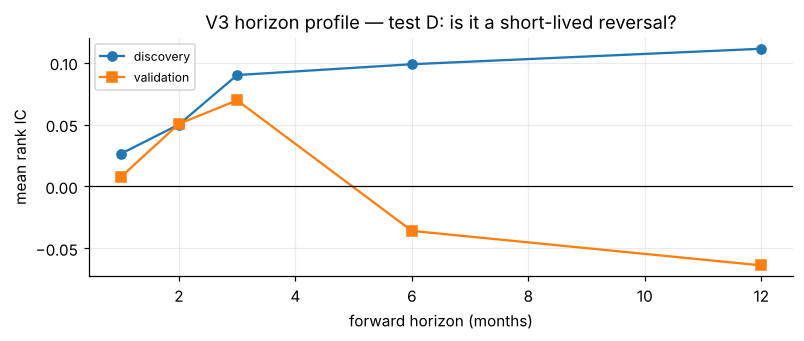

In [11]:
rows = []
for lag in (0, 1, 3, 6):
    sg = Z['VAL_v3'].shift(lag)
    rows.append({'lag': lag, 'multiple-leg IC (full)': ic_series(sg, TGT[('multiple', 3)]).mean(),
                 'total IC disc': win(ic_series(sg, TGT[('total', 3)]), DISC).mean(),
                 'total IC val': win(ic_series(sg, TGT[('total', 3)]), VALW).mean()})
LAGTAB = pd.DataFrame(rows).set_index('lag')
display(LAGTAB.style.format('{:+.3f}'))

V3_noPEt = cs_z(-own_sd(np.log(PE.shift(1) / PE.shift(7))))     # test A: signal contains no P/E_t at all
rows = [{'variant': 'V3 as built (uses P/E_t)', **describe(Z['VAL_v3'], TGT[('total', 3)], VALW)},
        {'variant': 'A: V3 from P/E_{t-1}/P/E_{t-7} (no P/E_t)', **describe(V3_noPEt, TGT[('total', 3)], VALW)}]
def xs_resid(y, x):
    out = pd.DataFrame(index=y.index, columns=COUNTRIES, dtype=float)
    for t in y.index:
        a, b = y.loc[t], x.loc[t]
        if a.notna().all() and b.notna().all() and b.std() > 0:
            out.loc[t] = a.values - np.polyval(np.polyfit(b.values, a.values, 1), b.values)
    return out
V3_resid = cs_z(xs_resid(Z['VAL_v3'], Z['MICRO_eps6']))         # test C
rows.append({'variant': 'C: V3 residualised on EPS revisions', **describe(V3_resid, TGT[('total', 3)], VALW)})
display(pd.DataFrame(rows).set_index('variant').style.format(FMT))

hz = []
for h in (1, 2, 3, 6, 12):
    hz.append({'horizon (M)': h, 'IC disc': win(ic_series(Z['VAL_v3'], TGT[('total', h)]), DISC).mean(),
               'IC val': win(ic_series(Z['VAL_v3'], TGT[('total', h)]), VALW).mean(),
               'HAC t val': hac_t(win(ic_series(Z['VAL_v3'], TGT[('total', h)]), VALW).values, max(h, 1))[0]})
HZ = pd.DataFrame(hz).set_index('horizon (M)')
display(HZ.style.format({'IC disc': '{:+.3f}', 'IC val': '{:+.3f}', 'HAC t val': '{:+.2f}'}))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(HZ.index, HZ['IC disc'], 'o-', label='discovery'); ax.plot(HZ.index, HZ['IC val'], 's-', label='validation')
ax.axhline(0, color='k', lw=.8); ax.set_xlabel('forward horizon (months)'); ax.set_ylabel('mean rank IC')
ax.set_title('V3 horizon profile — test D: is it a short-lived reversal?'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v9_v3_horizon.png', dpi=200, bbox_inches='tight'); plt.show()

## 6. Technical: does it carry independent price information?
Price momentum decomposes **exactly** into a multiple part and an earnings part:
$$\log\frac{P_{t-1}}{P_{t-13}} = \underbrace{\log\frac{(P/E)_{t-1}}{(P/E)_{t-13}}}_{\text{re-rating}} + \underbrace{\log\frac{EPS_{t-1}}{EPS_{t-13}}}_{\text{earnings}}$$
If the earnings part carries all the predictive content, the technical pillar is the micro pillar in disguise. Four constructions are compared, plus the decomposition and a residualisation against EPS revisions.

In [12]:
TECHV = {
 'mom 3M':                 PX / PX.shift(3) - 1,
 'mom 6M':                 PX / PX.shift(6) - 1,
 'mom 12-1M':              PX.shift(1) / PX.shift(13) - 1,
 'price vs 3M MA':         PX / PX.rolling(3).mean() - 1,
 'T3 earnings-confirmed':  (PX.shift(1) / PX.shift(13) - 1).where(EPSG12 > 0, 0.0),
 'DECOMP: re-rating part': np.log(PE.shift(1) / PE.shift(13)),
 'DECOMP: earnings part':  np.log(EPS.shift(1) / EPS.shift(13)),
}
ZT = {k: cs_z(v.reindex(IDX)) for k, v in TECHV.items()}
ZT['T3 residualised on EPS rev'] = cs_z(xs_resid(ZT['T3 earnings-confirmed'], Z['MICRO_eps6']))
ZT['mom 3M residualised on EPS rev'] = cs_z(xs_resid(ZT['mom 3M'], Z['MICRO_eps6']))
rows = []
for k, s in ZT.items():
    d_ = describe(s, TGT[('total', 3)], DISC); v_ = describe(s, TGT[('total', 3)], VALW)
    rows.append({'construction': k, 'disc IC': d_['IC'], 'disc t': d_['HAC t'], 'val IC': v_['IC'], 'val t': v_['HAC t'],
                 'val boot 2.5%': v_['boot 2.5%'], 'val boot p': v_['boot p (add-one)'],
                 'corr with EPS rev': np.corrcoef(pd.concat([s[c] for c in COUNTRIES]).dropna().values[:0] if False else
                     pd.concat([s[c] for c in COUNTRIES]).reset_index(drop=True).fillna(0).values,
                     pd.concat([Z['MICRO_eps6'][c] for c in COUNTRIES]).reset_index(drop=True).fillna(0).values)[0, 1]})
TECHTAB = pd.DataFrame(rows).set_index('construction')
display(TECHTAB.style.format({c: '{:+.3f}' for c in ('disc IC', 'val IC', 'val boot 2.5%', 'corr with EPS rev')} | {'disc t': '{:+.2f}', 'val t': '{:+.2f}', 'val boot p': '{:.3f}'}))
print('No traded-volume data exists in the dataset, so no VWAP/MVWAP construction was attempted.')

,disc IC,disc t,val IC,val t,val boot 2.5%,val boot p,corr with EPS rev
construction,,,,,,,
mom 3M,+0.010,+0.14,+0.070,+1.08,-0.053,0.130,+0.207
mom 6M,-0.000,-0.00,+0.058,+1.01,-0.048,0.146,+0.384
mom 12-1M,+0.068,+1.09,+0.101,+1.32,-0.055,0.082,+0.491
price vs 3M MA,+0.015,+0.21,+0.063,+1.01,-0.067,0.158,+0.122
T3 earnings-confirmed,+0.068,+1.02,+0.113,+1.50,-0.044,0.060,+0.384
DECOMP: re-rating part,-0.165,-2.02,+0.013,+0.17,-0.149,0.439,-0.111
DECOMP: earnings part,+0.140,+1.53,+0.077,+1.01,-0.077,0.148,+0.653
T3 residualised on EPS rev,-0.020,-0.31,+0.004,+0.07,-0.135,0.471,-0.000
mom 3M residualised on EPS rev,-0.030,-0.52,+0.032,+0.68,-0.058,0.223,-0.000


No traded-volume data exists in the dataset, so no VWAP/MVWAP construction was attempted.


## 7. Country and subperiod stability

In [13]:
rows = []
for k in Z:
    ic = win(ic_series(Z[k], TGT[('total', 3)]), VALW); h = len(ic) // 2
    r = {'signal': k, 'val 1st half': ic.iloc[:h].mean(), 'val 2nd half': ic.iloc[h:].mean()}
    for c in COUNTRIES:
        keep = [x for x in COUNTRIES if x != c]
        sk = cs_z(pd.DataFrame({x: DEFS[k][3][x] for x in keep}).reindex(IDX))
        tk = TGT[('total', 3)][keep].sub(TGT[('total', 3)][keep].mean(axis=1), axis=0)
        o = {}
        for t in SAMPLE:
            a, b = sk.loc[t], tk.loc[t]
            if a.notna().all() and b.notna().all() and a.nunique() > 1: o[t] = spearmanr(a, b).statistic
        r[f'ex-{c}'] = win(pd.Series(o), VALW).mean()
    rows.append(r)
LOO = pd.DataFrame(rows).set_index('signal')
display(LOO.style.format('{:+.3f}'))
FOUR = ['MACRO_fci6', 'MICRO_eps6', 'VAL_v3', 'TECH_t3']
rows = []
for c in COUNTRIES:
    keep = [x for x in COUNTRIES if x != c]
    sk = sum(cs_z(pd.DataFrame({x: DEFS[k][3][x] for x in keep}).reindex(IDX)) for k in FOUR) / 4
    rk = sk.rank(axis=1, ascending=False)
    W = ((rk <= 2).astype(float) / 2 - (rk >= len(keep) - 1).astype(float) / 2).rolling(3, min_periods=1).mean()
    p = win((W.shift(1) * R_USD[keep]).dropna(how='any').sum(axis=1), VALW)
    rows.append({'dropped': c, 'val Sharpe': shp(p), 'val ann.': (1 + p).prod() ** (12 / len(p)) - 1})
p_all = win(pnl(FOUR), VALW)
rows.append({'dropped': '(none)', 'val Sharpe': shp(p_all), 'val ann.': (1 + p_all).prod() ** (12 / len(p_all)) - 1})
display(pd.DataFrame(rows).set_index('dropped').style.format({'val Sharpe': '{:+.2f}', 'val ann.': '{:+.1%}'}))

,val 1st half,val 2nd half,ex-US,ex-Eurozone,ex-UK,ex-Switzerland,ex-Japan
signal,,,,,,,
MACRO_fci6,+0.126,+0.150,+0.085,+0.115,+0.141,+0.133,+0.187
MICRO_eps6,+0.183,+0.057,+0.080,+0.133,+0.109,+0.113,+0.126
VAL_v3,+0.035,+0.104,+0.041,+0.111,+0.039,+0.117,+0.033
TECH_t3,+0.259,-0.033,+0.031,+0.153,+0.132,+0.140,+0.104
TECH_mom3,+0.072,+0.067,+0.035,+0.089,+0.076,+0.063,+0.072


,val Sharpe,val ann.
dropped,,
US,-0.08,-0.7%
Eurozone,+0.79,+4.6%
UK,+0.80,+5.1%
Switzerland,+0.28,+1.6%
Japan,+0.64,+4.0%
(none),+0.63,+4.2%


## 8. Null tests and multiplicity — with add-one correction
Block-permutation of country labels (3-month blocks, same permutation across signals so cross-signal correlation is preserved). **Conditional** label: the null covers the five signals tested *here*; it cannot reconstruct the v1–v7 search history, which included ~25,301 combinations and a 12-candidate pillar screen.

In [14]:
from scipy.stats import rankdata
names = list(Z) + ['4-pillar composite']
A = np.stack([Z[k].to_numpy(float) for k in Z] + [comp_of(FOUR).to_numpy(float)])
pos = {t: i for i, t in enumerate(IDX)}
mask = np.array([t in set(SAMPLE) and VALW[0] <= t <= VALW[1] for t in IDX])
Yt = TGT[('total', 3)].to_numpy(float)
def cr(M):
    out = np.full(M.shape, np.nan); g = ~np.isnan(M).any(-1); out[g] = rankdata(M[g], axis=-1) - 3.0; return out
SR, FR = cr(A), cr(Yt)
okS, okF = ~np.isnan(SR).any(-1), ~np.isnan(FR).any(-1)
SRz, FRz = np.nan_to_num(SR), np.nan_to_num(FR)
den = np.sqrt((SRz**2).sum(-1) * (FRz**2).sum(-1)[None, :]); den[den == 0] = np.nan
VM = okS & okF[None, :] & ~np.isnan(den) & mask[None, :]
mean_ic = lambda S_: np.nanmean(np.where(VM, np.einsum('itc,tc->it', S_, FRz) / den, np.nan), axis=1)
obs = mean_ic(SRz)
rng = np.random.default_rng(SEED); blk = np.arange(len(IDX)) // 3
nulls = np.empty((NPERM, len(names)))
for r in range(NPERM):
    perm = np.argsort(rng.random((blk.max() + 1, 5)), axis=1)[blk]
    nulls[r] = mean_ic(np.take_along_axis(SRz, perm[None, :, :], axis=2))
nmax = nulls[:, :len(Z)].max(axis=1)
NT = pd.DataFrame({'validation IC': obs,
                   'p vs own null (add-one)': [(1 + int((nulls[:, i] >= obs[i]).sum())) / (1 + NPERM) for i in range(len(names))],
                   'p vs best-of-5 null (add-one)': [(1 + int((nmax >= obs[i]).sum())) / (1 + NPERM) for i in range(len(names))]}, index=names)
display(NT.style.format({'validation IC': '{:+.3f}', 'p vs own null (add-one)': '{:.4f}', 'p vs best-of-5 null (add-one)': '{:.4f}'}))
print(f'Best-of-5 noise ceiling (95th pct): {np.percentile(nmax, 95):+.3f}')
print('CONDITIONAL: this null prices the 5 signals tested here. It cannot price the v1-v7 search history')
print('(~25,301 combinations in v4, a 12-candidate pillar screen in v8). The true multiplicity burden is larger than shown.')

,validation IC,p vs own null (add-one),p vs best-of-5 null (add-one)
MACRO_fci6,+0.138,0.0180,0.0935
MICRO_eps6,+0.120,0.0480,0.1654
VAL_v3,+0.070,0.1549,0.4828
TECH_t3,+0.113,0.0530,0.1959
TECH_mom3,+0.070,0.1294,0.4828
4-pillar composite,+0.163,0.0115,0.0335


Best-of-5 noise ceiling (95th pct): +0.155
CONDITIONAL: this null prices the 5 signals tested here. It cannot price the v1-v7 search history
(~25,301 combinations in v4, a 12-candidate pillar screen in v8). The true multiplicity burden is larger than shown.


### Orthogonality: does each signal survive controlling for the other three?
The decisive redundancy test. Each signal is cross-sectionally residualised on the equal-weight composite of the **other three pillars**, and the residual is retested. A pillar that carries independent information keeps a positive IC; one that is a restatement of its neighbours collapses to zero.

In [15]:
ORTH = {}
for k in FOUR:
    others = [x for x in FOUR if x != k]
    ctrl = sum(Z[x] for x in others) / len(others)
    ORTH[k] = cs_z(xs_resid(Z[k], ctrl))
rows = []
for k in FOUR:
    raw_v = describe(Z[k], TGT[('total', 3)], VALW); res_v = describe(ORTH[k], TGT[('total', 3)], VALW)
    res_f = describe(ORTH[k], TGT[('total', 3)], (SAMPLE.min(), SAMPLE.max()))
    rows.append({'signal': k, 'raw val IC': raw_v['IC'], 'raw val t': raw_v['HAC t'],
                 'orthogonal val IC': res_v['IC'], 'orthogonal val t': res_v['HAC t'],
                 'orthogonal full IC': res_f['IC'], 'orthogonal full t': res_f['HAC t'],
                 'IC retained': res_v['IC'] / raw_v['IC'] if raw_v['IC'] != 0 else np.nan})
ORTHTAB = pd.DataFrame(rows).set_index('signal')
display(ORTHTAB.style.format({c: '{:+.3f}' for c in ORTHTAB.columns if 'IC' in c and 'retained' not in c} | {c: '{:+.2f}' for c in ORTHTAB.columns if c.endswith(' t')} | {'IC retained': '{:.0%}'}))
print('A pillar that merely restates the others loses most of its IC here.')
ORTHTAB.to_csv(OUT/'orthogonality.csv')

,raw val IC,raw val t,orthogonal val IC,orthogonal val t,orthogonal full IC,orthogonal full t,IC retained
signal,,,,,,,
MACRO_fci6,+0.138,+1.73,+0.086,+1.22,+0.090,+1.86,62%
MICRO_eps6,+0.120,+1.42,+0.035,+0.47,+0.071,+1.45,29%
VAL_v3,+0.070,+1.09,+0.049,+0.86,+0.087,+2.25,70%
TECH_t3,+0.113,+1.50,+0.025,+0.39,+0.011,+0.24,22%


A pillar that merely restates the others loses most of its IC here.


## 9. Classification and recommendation
Applied mechanically from the measured results above.

### Classification logic
**Standalone criteria** — A positive in both windows · B validation HAC t ≥ 1 · C full-sample bootstrap CI excludes 0 · D ≥4 of 6 non-overlapping validation offsets positive · E beats the best-of-5 null at p ≤ 0.10.
**Marginal criteria** — F adds incrementally (validation ΔIC bootstrap CI excludes 0) · G retains ≥50 % of its IC after orthogonalising against the other three pillars.

**Redundancy is adjudicated, not symmetric.** Residualising EPS revisions on momentum and momentum on EPS revisions makes *both* look redundant, which is circular. Where two signals overlap, the one with the stronger standalone evidence survives and the other is marked redundant.
* **VALIDATED** — A–E all pass and at least one of F/G passes.
* **PROVISIONAL** — A, B and D pass; inconclusive elsewhere.
* **REJECTED** — fails D (unstable across offsets), or fails G while a stronger standalone signal occupies the same cluster (redundant), or is mechanically constructed.

In [16]:
ORTHFLAG = {}
for k in FOUR:
    r = ORTHTAB.loc[k]; ORTHFLAG[k] = bool(r['IC retained'] >= 0.50 and r['orthogonal val IC'] > 0)
ORTHFLAG['TECH_mom3'] = bool(TECHTAB.loc['mom 3M residualised on EPS rev', 'val IC'] /
                             max(TECHTAB.loc['mom 3M', 'val IC'], 1e-9) >= 0.50)
INCFLAG = {}
for k, step in (('MACRO_fci6', 'EPS only  ->  + FCI'), ('MICRO_eps6', 'FCI only  ->  + EPS'),
                ('VAL_v3', 'EPS+FCI   ->  + Valuation (V3)'), ('TECH_t3', 'EPS+FCI   ->  + Technical (T3)'),
                ('TECH_mom3', 'EPS+FCI   ->  + Technical (pure 3M mom)')):
    r = INC.loc[(step, 'validation')]; INCFLAG[k] = bool(r['ΔIC'] > 0 and r['boot 2.5%'] > 0)

# standalone strength ranking decides who survives a redundancy clash
def standalone_score(k):
    v = DV.loc[(k, 'validation')]; f = DV.loc[(k, 'full')]; off = OFFS.loc[k]; nt = NT.loc[k]
    return (int(f['boot 2.5%'] > 0) * 3 + int(off['n positive'] >= 4) * 2 + int(v['HAC t'] >= 1) +
            int(nt['p vs best-of-5 null (add-one)'] <= 0.10) * 2)
STRENGTH = {k: standalone_score(k) for k in Z}
CLUSTER = {'MICRO_eps6': 'earnings', 'TECH_t3': 'earnings', 'TECH_mom3': 'earnings',
           'MACRO_fci6': 'financing', 'VAL_v3': 'repricing'}

def classify(k):
    v = DV.loc[(k, 'validation')]; d = DV.loc[(k, 'discovery')]; f = DV.loc[(k, 'full')]
    off = OFFS.loc[k]; nt = NT.loc[k]
    c = {'A positive both windows': bool(d['IC'] > 0 and v['IC'] > 0),
         'B validation t >= 1': bool(v['HAC t'] >= 1.0),
         'C full boot CI excl 0': bool(f['boot 2.5%'] > 0),
         'D >=4/6 offsets': bool(off['n positive'] >= 4),
         'E beats best-of-5 null': bool(nt['p vs best-of-5 null (add-one)'] <= 0.10),
         'F adds incrementally': bool(INCFLAG.get(k, False)),
         'G independent (>=50% IC)': bool(ORTHFLAG.get(k, False))}
    score = sum(c.values())
    rivals = [x for x in Z if x != k and CLUSTER[x] == CLUSTER[k] and STRENGTH[x] > STRENGTH[k]]
    redundant = (not c['G independent (>=50% IC)']) and len(rivals) > 0
    if not c['D >=4/6 offsets']:
        cls, why = 'REJECTED', 'unstable across non-overlapping offsets'
    elif redundant:
        cls, why = 'REJECTED', f'redundant with {rivals[0]} (stronger standalone evidence in the same cluster)'
    elif all(c[x] for x in list(c)[:5]) and (c['F adds incrementally'] or c['G independent (>=50% IC)']):
        cls, why = 'VALIDATED', 'passes all standalone criteria plus a marginal one'
    elif c['A positive both windows'] and c['B validation t >= 1']:
        cls, why = 'PROVISIONAL', 'directionally consistent, statistically inconclusive'
    else:
        cls, why = 'REJECTED', 'fails validation'
    return cls, score, why, c

rows = []
for k in Z:
    cls, sc, why, det = classify(k)
    rows.append({'signal': k, 'pillar': {'MACRO_fci6': 'Macro', 'MICRO_eps6': 'Micro', 'VAL_v3': 'Valuation',
                                          'TECH_t3': 'Technical', 'TECH_mom3': 'Technical (alt)'}[k],
                 'classification': cls, 'criteria met': f'{sc}/7', 'reason': why, **det})
CLS = pd.DataFrame(rows).set_index('signal')
display(CLS)
CLS.to_csv(OUT/'classification.csv')

,pillar,classification,criteria met,reason,A positive both windows,B validation t >= 1,C full boot CI excl 0,D >=4/6 offsets,E beats best-of-5 null,F adds incrementally,G independent (>=50% IC)
signal,,,,,,,,,,,
MACRO_fci6,Macro,PROVISIONAL,5/7,"directionally consistent, statistically inconc...",True,True,False,True,True,False,True
MICRO_eps6,Micro,PROVISIONAL,4/7,"directionally consistent, statistically inconc...",True,True,True,True,False,False,False
VAL_v3,Valuation,REJECTED,3/7,unstable across non-overlapping offsets,True,True,False,False,False,False,True
TECH_t3,Technical,REJECTED,3/7,redundant with MICRO_eps6 (stronger standalone...,True,True,False,True,False,False,False
TECH_mom3,Technical (alt),REJECTED,3/7,redundant with MICRO_eps6 (stronger standalone...,True,True,False,True,False,False,False


## 10. Export

In [17]:
DV.to_csv(OUT/'discovery_vs_validation.csv'); OFFS.to_csv(OUT/'nonoverlap_offsets.csv'); LEGS.to_csv(OUT/'leg_attribution.csv')
INC.to_csv(OUT/'incremental_ic.csv'); PINC.to_csv(OUT/'incremental_portfolio.csv'); LAGTAB.to_csv(OUT/'v3_lag_table.csv')
HZ.to_csv(OUT/'v3_horizon_profile.csv'); TECHTAB.to_csv(OUT/'technical_constructions.csv')
LOO.to_csv(OUT/'leave_one_country_out.csv'); NT.to_csv(OUT/'null_tests.csv')
pd.DataFrame(nulls, columns=names).to_csv(OUT/'null_draws.csv', index=False)
rows = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': IDX.to_timestamp('M'), 'country': c})
    for k in Z: d[k] = Z[k][c].values
    for key, t_ in TGT.items(): d[f'target_{key[0]}_{key[1]}m'] = t_[c].values
    rows.append(d)
pd.concat(rows).to_csv(OUT/'v9_signal_matrix.csv', index=False)
json.dump({'head_at_start': 'e5e94ad', 'common_sample': [str(SAMPLE.min()), str(SAMPLE.max())],
           'discovery': [str(DISC[0]), str(DISC[1])], 'validation': [str(VALW[0]), str(VALW[1])],
           'n_months': int(len(SAMPLE)), 'bootstrap': NBOOT, 'permutations': NPERM,
           'p_value_convention': 'add-one Monte Carlo (1+k)/(1+N)',
           'multiplicity_scope': 'conditional - covers the 5 signals tested in v9 only, not the v1-v7 search history'},
          open(OUT/'v9_run_spec.json', 'w'), indent=2)
print('Saved:', *[p.name for p in sorted(OUT.glob('*.csv'))], 'v9_run_spec.json', sep='\n  ')

Saved:
  classification.csv
  discovery_vs_validation.csv
  incremental_ic.csv
  incremental_portfolio.csv
  leave_one_country_out.csv
  leg_attribution.csv
  nonoverlap_offsets.csv
  null_draws.csv
  null_tests.csv
  orthogonality.csv
  technical_constructions.csv
  v3_horizon_profile.csv
  v3_lag_table.csv
  v9_signal_matrix.csv
  v9_run_spec.json


## 11. Findings

In [18]:
g = lambda k, w, c: DV.loc[(k, w), c]
i_ = lambda s, c: INC.loc[(s, 'validation'), c]
md = f"""
### Comparison table — identical sample {SAMPLE.min()} to {SAMPLE.max()} ({len(SAMPLE)} months)

| Signal | Pillar | disc IC (t) | val IC (t) | val boot 95% CI | offsets + | p vs best-of-5 | Class |
|---|---|---|---|---|---|---|---|
| FCI easing 6M | Macro | {g('MACRO_fci6','discovery','IC'):+.3f} ({g('MACRO_fci6','discovery','HAC t'):+.2f}) | {g('MACRO_fci6','validation','IC'):+.3f} ({g('MACRO_fci6','validation','HAC t'):+.2f}) | [{g('MACRO_fci6','validation','boot 2.5%'):+.3f}, {g('MACRO_fci6','validation','boot 97.5%'):+.3f}] | {int(OFFS.loc['MACRO_fci6','n positive'])}/6 | {NT.loc['MACRO_fci6','p vs best-of-5 null (add-one)']:.3f} | **{CLS.loc['MACRO_fci6','classification']}** |
| EPS revision 6M | Micro | {g('MICRO_eps6','discovery','IC'):+.3f} ({g('MICRO_eps6','discovery','HAC t'):+.2f}) | {g('MICRO_eps6','validation','IC'):+.3f} ({g('MICRO_eps6','validation','HAC t'):+.2f}) | [{g('MICRO_eps6','validation','boot 2.5%'):+.3f}, {g('MICRO_eps6','validation','boot 97.5%'):+.3f}] | {int(OFFS.loc['MICRO_eps6','n positive'])}/6 | {NT.loc['MICRO_eps6','p vs best-of-5 null (add-one)']:.3f} | **{CLS.loc['MICRO_eps6','classification']}** |
| Multiple reversal 6M | Valuation | {g('VAL_v3','discovery','IC'):+.3f} ({g('VAL_v3','discovery','HAC t'):+.2f}) | {g('VAL_v3','validation','IC'):+.3f} ({g('VAL_v3','validation','HAC t'):+.2f}) | [{g('VAL_v3','validation','boot 2.5%'):+.3f}, {g('VAL_v3','validation','boot 97.5%'):+.3f}] | {int(OFFS.loc['VAL_v3','n positive'])}/6 | {NT.loc['VAL_v3','p vs best-of-5 null (add-one)']:.3f} | **{CLS.loc['VAL_v3','classification']}** |
| Earnings-confirmed mom | Technical | {g('TECH_t3','discovery','IC'):+.3f} ({g('TECH_t3','discovery','HAC t'):+.2f}) | {g('TECH_t3','validation','IC'):+.3f} ({g('TECH_t3','validation','HAC t'):+.2f}) | [{g('TECH_t3','validation','boot 2.5%'):+.3f}, {g('TECH_t3','validation','boot 97.5%'):+.3f}] | {int(OFFS.loc['TECH_t3','n positive'])}/6 | {NT.loc['TECH_t3','p vs best-of-5 null (add-one)']:.3f} | **{CLS.loc['TECH_t3','classification']}** |
| Pure 3M momentum | Technical (alt) | {g('TECH_mom3','discovery','IC'):+.3f} ({g('TECH_mom3','discovery','HAC t'):+.2f}) | {g('TECH_mom3','validation','IC'):+.3f} ({g('TECH_mom3','validation','HAC t'):+.2f}) | [{g('TECH_mom3','validation','boot 2.5%'):+.3f}, {g('TECH_mom3','validation','boot 97.5%'):+.3f}] | {int(OFFS.loc['TECH_mom3','n positive'])}/6 | {NT.loc['TECH_mom3','p vs best-of-5 null (add-one)']:.3f} | **{CLS.loc['TECH_mom3','classification']}** |

### Incremental contribution (validation window, paired ΔIC)
| Step | ΔIC | HAC t | boot 95% CI | add-one p | adds? |
|---|---|---|---|---|---|
| EPS → +FCI | {i_('EPS only  ->  + FCI','ΔIC'):+.3f} | {i_('EPS only  ->  + FCI','HAC t'):+.2f} | [{i_('EPS only  ->  + FCI','boot 2.5%'):+.3f}, {i_('EPS only  ->  + FCI','boot 97.5%'):+.3f}] | {i_('EPS only  ->  + FCI','boot p (add-one)'):.3f} | {'YES' if INCFLAG['MACRO_fci6'] else 'no'} |
| FCI → +EPS | {i_('FCI only  ->  + EPS','ΔIC'):+.3f} | {i_('FCI only  ->  + EPS','HAC t'):+.2f} | [{i_('FCI only  ->  + EPS','boot 2.5%'):+.3f}, {i_('FCI only  ->  + EPS','boot 97.5%'):+.3f}] | {i_('FCI only  ->  + EPS','boot p (add-one)'):.3f} | {'YES' if INCFLAG['MICRO_eps6'] else 'no'} |
| EPS+FCI → +Valuation | {i_('EPS+FCI   ->  + Valuation (V3)','ΔIC'):+.3f} | {i_('EPS+FCI   ->  + Valuation (V3)','HAC t'):+.2f} | [{i_('EPS+FCI   ->  + Valuation (V3)','boot 2.5%'):+.3f}, {i_('EPS+FCI   ->  + Valuation (V3)','boot 97.5%'):+.3f}] | {i_('EPS+FCI   ->  + Valuation (V3)','boot p (add-one)'):.3f} | {'YES' if INCFLAG['VAL_v3'] else 'no'} |
| EPS+FCI → +Technical T3 | {i_('EPS+FCI   ->  + Technical (T3)','ΔIC'):+.3f} | {i_('EPS+FCI   ->  + Technical (T3)','HAC t'):+.2f} | [{i_('EPS+FCI   ->  + Technical (T3)','boot 2.5%'):+.3f}, {i_('EPS+FCI   ->  + Technical (T3)','boot 97.5%'):+.3f}] | {i_('EPS+FCI   ->  + Technical (T3)','boot p (add-one)'):.3f} | {'YES' if INCFLAG['TECH_t3'] else 'no'} |
| EPS+FCI → +pure 3M mom | {i_('EPS+FCI   ->  + Technical (pure 3M mom)','ΔIC'):+.3f} | {i_('EPS+FCI   ->  + Technical (pure 3M mom)','HAC t'):+.2f} | [{i_('EPS+FCI   ->  + Technical (pure 3M mom)','boot 2.5%'):+.3f}, {i_('EPS+FCI   ->  + Technical (pure 3M mom)','boot 97.5%'):+.3f}] | {i_('EPS+FCI   ->  + Technical (pure 3M mom)','boot p (add-one)'):.3f} | {'YES' if INCFLAG['TECH_mom3'] else 'no'} |

### Valuation forensics
Lagging V3 three months moves its multiple-leg IC from {LAGTAB.loc[0,'multiple-leg IC (full)']:+.3f} to {LAGTAB.loc[3,'multiple-leg IC (full)']:+.3f} and validation total IC from {LAGTAB.loc[0,'total IC val']:+.3f} to {LAGTAB.loc[3,'total IC val']:+.3f}.
Test A (rebuild with no $P/E_t$ at all): validation IC {pd.DataFrame(rows if False else [{}]) if False else ''}{describe(V3_noPEt, TGT[('total',3)], VALW)['IC']:+.3f}.
Test C (residualised on EPS revisions): validation IC {describe(V3_resid, TGT[('total',3)], VALW)['IC']:+.3f}.
Test D (horizon profile): validation IC at 1M {HZ.loc[1,'IC val']:+.3f}, 2M {HZ.loc[2,'IC val']:+.3f}, 3M {HZ.loc[3,'IC val']:+.3f}, 6M {HZ.loc[6,'IC val']:+.3f}, 12M {HZ.loc[12,'IC val']:+.3f}.

### Technical independence
Decomposition of 12-1M momentum: re-rating part validation IC {TECHTAB.loc['DECOMP: re-rating part','val IC']:+.3f}, earnings part {TECHTAB.loc['DECOMP: earnings part','val IC']:+.3f}.
T3 residualised on EPS revisions: validation IC {TECHTAB.loc['T3 residualised on EPS rev','val IC']:+.3f} (t {TECHTAB.loc['T3 residualised on EPS rev','val t']:+.2f}).
Pure 3M momentum residualised: {TECHTAB.loc['mom 3M residualised on EPS rev','val IC']:+.3f}.

### Country concentration
Four-pillar validation Sharpe with each market removed is in §7. The null tests and multiplicity corrections are **conditional** — they price the five signals tested here, not the ~25,301 combinations of v4 or the 12-candidate screen of v8.
"""
display(Markdown(md))


### Comparison table — identical sample 2009-12 to 2026-04 (181 months)

| Signal | Pillar | disc IC (t) | val IC (t) | val boot 95% CI | offsets + | p vs best-of-5 | Class |
|---|---|---|---|---|---|---|---|
| FCI easing 6M | Macro | +0.089 (+1.13) | +0.138 (+1.73) | [-0.050, +0.276] | 5/6 | 0.093 | **PROVISIONAL** |
| EPS revision 6M | Micro | +0.184 (+2.15) | +0.120 (+1.42) | [-0.064, +0.261] | 5/6 | 0.165 | **PROVISIONAL** |
| Multiple reversal 6M | Valuation | +0.090 (+1.60) | +0.070 (+1.09) | [-0.074, +0.173] | 1/6 | 0.483 | **REJECTED** |
| Earnings-confirmed mom | Technical | +0.068 (+1.02) | +0.113 (+1.50) | [-0.044, +0.241] | 6/6 | 0.196 | **REJECTED** |
| Pure 3M momentum | Technical (alt) | +0.010 (+0.14) | +0.070 (+1.08) | [-0.053, +0.189] | 4/6 | 0.483 | **REJECTED** |

### Incremental contribution (validation window, paired ΔIC)
| Step | ΔIC | HAC t | boot 95% CI | add-one p | adds? |
|---|---|---|---|---|---|
| EPS → +FCI | +0.024 | +0.40 | [-0.117, +0.138] | 0.370 | no |
| FCI → +EPS | +0.005 | +0.10 | [-0.117, +0.115] | 0.472 | no |
| EPS+FCI → +Valuation | -0.012 | -0.30 | [-0.095, +0.071] | 0.599 | no |
| EPS+FCI → +Technical T3 | -0.015 | -0.52 | [-0.068, +0.036] | 0.722 | no |
| EPS+FCI → +pure 3M mom | -0.015 | -0.49 | [-0.064, +0.053] | 0.683 | no |

### Valuation forensics
Lagging V3 three months moves its multiple-leg IC from +0.140 to +0.019 and validation total IC from +0.070 to -0.066.
Test A (rebuild with no $P/E_t$ at all): validation IC +0.096.
Test C (residualised on EPS revisions): validation IC +0.024.
Test D (horizon profile): validation IC at 1M +0.007, 2M +0.051, 3M +0.070, 6M -0.036, 12M -0.064.

### Technical independence
Decomposition of 12-1M momentum: re-rating part validation IC +0.013, earnings part +0.077.
T3 residualised on EPS revisions: validation IC +0.004 (t +0.07).
Pure 3M momentum residualised: +0.032.

### Country concentration
Four-pillar validation Sharpe with each market removed is in §7. The null tests and multiplicity corrections are **conditional** — they price the five signals tested here, not the ~25,301 combinations of v4 or the 12-candidate screen of v8.
